# 02 · Customers and stores

Who buys, who stopped buying, and whether the store network matches where customers are.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from utils import *

orders = load_orders()
customers = read("customers.csv")
print(f"{len(customers):,} registered customers")
print(f"Orders with no customer ID: {orders['customer_id'].isna().mean():.0%}")

85,000 registered customers
Orders with no customer ID: 19%


## 1. The customer base

In [2]:
known = orders[orders["customer_id"].notna()]
cust = known.groupby("customer_id").agg(
    first_order=("order_date", "min"),
    last_order=("order_date", "max"),
    orders=("sales_order_id", "count"),
    net_sales=("net_before_tax_EGP", "sum"),
).reset_index()

as_of = orders["order_date"].max()
cust["days_since_last"] = (as_of - cust["last_order"]).dt.days

print("Bought at least once:", len(cust))
print("Never bought:", len(customers) - len(cust))
print(f"Repeat buyers: {(cust['orders'] > 1).mean():.0%}")
print(f"Average orders per buyer: {cust['orders'].mean():.1f}")

Bought at least once: 74660
Never bought: 10340
Repeat buyers: 87%
Average orders per buyer: 5.9


## 2. RFM segments

Recency and frequency scored 1-5 (quintiles). Monetary isn't scored because inflation makes old spending look tiny.

In [3]:
cust["R"] = pd.qcut(cust["days_since_last"].rank(method="first"), 5, labels=[5, 4, 3, 2, 1]).astype(int)
cust["F"] = pd.qcut(cust["orders"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)


def segment(row):
    if row.R >= 4 and row.F >= 4:
        return "Champions"
    if row.R >= 3 and row.F >= 3:
        return "Loyal"
    if row.R >= 4:
        return "New / Promising"
    if row.R <= 2 and row.F >= 3:
        return "At Risk"
    if row.R <= 2:
        return "Lost"
    return "Needs Attention"


cust["segment"] = cust.apply(segment, axis=1)

fy26_spend = known[known["FY"] == 2026].groupby("customer_id")["net_before_tax_EGP"].sum()
cust["fy26_sales"] = cust["customer_id"].map(fy26_spend).fillna(0)

seg = cust.groupby("segment").agg(customers=("customer_id", "count"), net_sales=("net_sales", "sum"),
                                  fy26_sales=("fy26_sales", "sum"), days_since_last=("days_since_last", "median"),
                                  avg_orders=("orders", "mean"))
seg["% customers"] = seg["customers"] / seg["customers"].sum() * 100
seg["% revenue (8 yrs)"] = seg["net_sales"] / seg["net_sales"].sum() * 100
seg["% revenue (FY26)"] = seg["fy26_sales"] / seg["fy26_sales"].sum() * 100
seg = seg.sort_values("net_sales", ascending=False)
seg[["customers", "% customers", "% revenue (8 yrs)", "% revenue (FY26)", "days_since_last", "avg_orders"]].round(1)

,customers,% customers,% revenue (8 yrs),% revenue (FY26),days_since_last,avg_orders
segment,,,,,,
Champions,13012,17.4,29.0,31.5,78.0,10.1
Loyal,15039,20.1,25.9,31.3,190.0,6.9
At Risk,16745,22.4,24.3,5.9,490.0,8.3
New / Promising,10890,14.6,8.7,18.4,80.0,2.1
Lost,13119,17.6,7.5,3.6,537.0,2.1
Needs Attention,5855,7.8,4.5,9.3,226.0,2.1


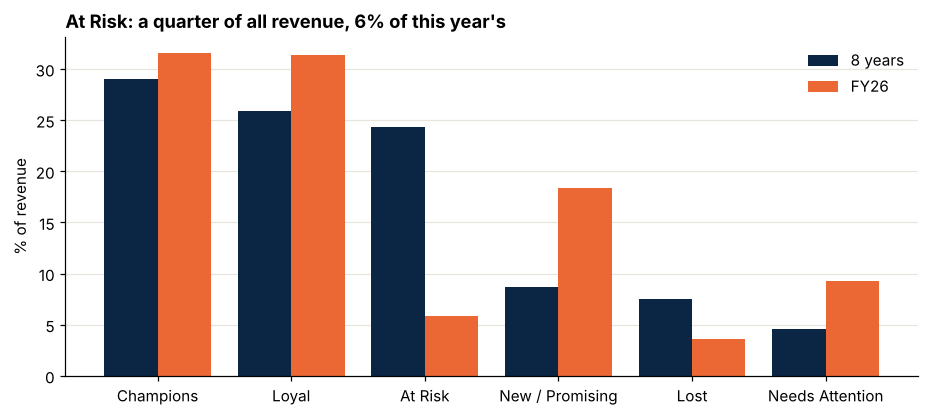

In [4]:
x = np.arange(len(seg))
plt.figure(figsize=(10, 4))
plt.bar(x - 0.2, seg["% revenue (8 yrs)"], 0.4, color=NAVY, label="8 years")
plt.bar(x + 0.2, seg["% revenue (FY26)"], 0.4, color=ORANGE, label="FY26")
plt.xticks(x, seg.index)
plt.ylabel("% of revenue")
plt.title("At Risk: a quarter of all revenue, 6% of this year's")
plt.legend()
save("02_rfm")
plt.show()

## 3. Retention by first-purchase year

In [5]:
known8 = known[known["FY"].between(2019, 2026)]
first_year = known8.groupby("customer_id")["FY"].min()
active = known8[["customer_id", "FY"]].drop_duplicates()
active["cohort"] = active["customer_id"].map(first_year)
active["years_later"] = active["FY"] - active["cohort"]

cohorts = active.groupby(["cohort", "years_later"])["customer_id"].nunique().unstack()
retention = (cohorts.div(cohorts[0], axis=0) * 100).round(0)
retention

years_later,0,1,2,3,4,5,6,7
cohort,,,,,,,,
2019,100.0,91.0,80.0,73.0,70.0,68.0,66.0,65.0
2020,100.0,81.0,73.0,69.0,68.0,66.0,64.0,NaN
2021,100.0,72.0,69.0,67.0,66.0,65.0,NaN,NaN
2022,100.0,69.0,67.0,65.0,64.0,NaN,NaN,NaN
2023,100.0,67.0,65.0,64.0,NaN,NaN,NaN,NaN
2024,100.0,65.0,64.0,NaN,NaN,NaN,NaN,NaN
2025,100.0,64.0,NaN,NaN,NaN,NaN,NaN,NaN
2026,100.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN


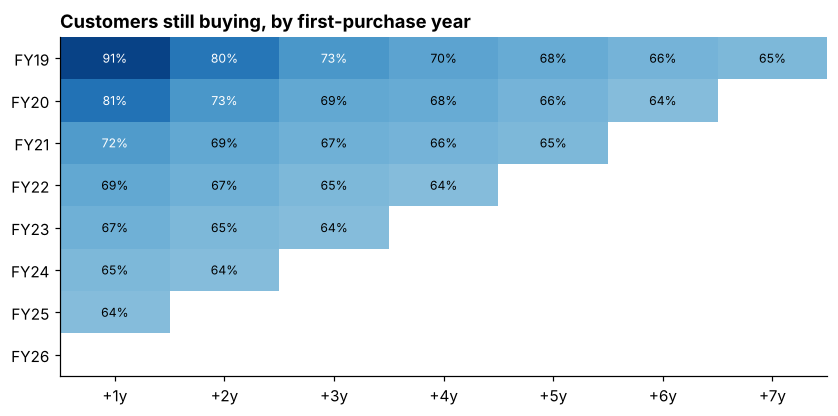

In [6]:
plt.figure(figsize=(9, 4))
plt.imshow(retention.iloc[:, 1:], cmap="Blues", vmin=40, vmax=95, aspect="auto")
for i in range(retention.shape[0]):
    for j in range(1, retention.shape[1]):
        v = retention.iloc[i, j]
        if not np.isnan(v):
            plt.text(j - 1, i, f"{v:.0f}%", ha="center", va="center", fontsize=8, color="white" if v > 70 else "black")
plt.xticks(range(retention.shape[1] - 1), [f"+{k}y" for k in range(1, retention.shape[1])])
plt.yticks(range(len(retention)), [f"FY{str(c)[2:]}" for c in retention.index])
plt.grid(False)
plt.title("Customers still buying, by first-purchase year")
save("02_cohorts")
plt.show()

Year-1 retention dropped from 91% to 64%, but whoever stays, stays (~64% long term).

## 4. Customers vs branches by governorate

In [7]:
branches = read("branches.csv")
gov = pd.DataFrame({
    "customers": customers.groupby("governorate_ar").size(),
    "branches": branches.groupby("governorate_ar").size(),
})
gov["customers_per_branch"] = gov["customers"] / gov["branches"]
gov.sort_values("customers_per_branch", ascending=False)

,customers,branches,customers_per_branch
governorate_ar,,,
البحر الأحمر,4007,1,4007.000000
مطروح,3996,1,3996.000000
قنا,3994,1,3994.000000
أسيوط,4134,2,2067.000000
سوهاج,4126,2,2063.000000
كفر الشيخ,4125,2,2062.500000
الفيوم,4060,2,2030.000000
بني سويف,4053,2,2026.500000
أسوان,4012,2,2006.000000


Customers are spread evenly (~4,000 per governorate), branches aren't: Cairo has 21 branches
(192 customers each), while Red Sea, Matrouh and Qena have ~4,000 customers for one branch.

In [8]:
by_branch = orders[orders["FY"].between(2019, 2026)].groupby("branch_id")["net_before_tax_EGP"].sum()
spread = by_branch / by_branch.mean()
print(f"Branch sales range: {spread.min():.2f}x to {spread.max():.2f}x the average (CV {by_branch.std() / by_branch.mean():.1%})")

Branch sales range: 0.94x to 1.09x the average (CV 3.1%)


Branches are within ±6% of each other, which is too even to rank them.

**Summary:** loyal base, a large lapsing At Risk group, 10,340 registered non-buyers, and a store network built around Cairo.